# Credit Card Default Risk: An Explainable, Fairness-Checked Model

**Business problem:** a card issuer wants to know, a month ahead, which customers are likely to miss their next payment so a collections or financial-support team can contact them early. The team can only reach a fraction of customers, so the model has to *rank* well. Because this is a credit decision, it also has to be **explainable** (every flagged customer needs reasons) and **checked for unfair outcomes** across groups such as sex and age.

**Data:** *Default of Credit Card Clients* (Yeh & Lien, 2009; UCI Machine Learning Repository, CC BY 4.0): 30,000 credit card customers of a Taiwanese bank in 2005, with credit limit, demographics, six months of repayment status, bill amounts and payments, and whether they defaulted the following month. Amounts are in New Taiwan dollars.

**Tools:** Python (pandas, scikit-learn, XGBoost, SHAP, matplotlib).

**What this notebook does**
1. Checks data quality, including undocumented category codes
2. Engineers behavioural features (utilisation, months late, payment ratio)
3. Compares an interpretable baseline (logistic regression) against gradient-boosted trees (XGBoost), with 5-fold cross-validation and a held-out test set
4. Checks calibration: does a 30% score mean a 30% default rate?
5. Explains the model globally and per customer with SHAP (reason codes)
6. Tests fairness: does the model flag men and women, and different age groups, at similar rates and with similar error rates?

In [1]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
os.makedirs("images", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)

import warnings; warnings.filterwarnings("ignore")
import xgboost as xgb, shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from sklearn.calibration import calibration_curve

DATA_PATH = "data/uci_credit_card.csv"
if not os.path.exists(DATA_PATH):
    # Mirror of the UCI file (Git LFS); SHA-256 a0f0ab49...9ca1
    urllib.request.urlretrieve("https://media.githubusercontent.com/media/gabrieloa/augmentation-effective/main/data/UCI_Credit_Card.csv", DATA_PATH)
raw = pd.read_csv(DATA_PATH).rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"})
print(raw.shape)
raw.head(3)

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,"20,000.000",2,2,1,24,2,2,-1,-1,...,0.000,0.000,0.000,0.000,689.000,0.000,0.000,0.000,0.000,1
1,2,"120,000.000",2,2,2,26,-1,2,0,0,...,"3,272.000","3,455.000","3,261.000",0.000,"1,000.000","1,000.000","1,000.000",0.000,"2,000.000",1
2,3,"90,000.000",2,2,2,34,0,0,0,0,...,"14,331.000","14,948.000","15,549.000","1,518.000","1,500.000","1,000.000","1,000.000","1,000.000","5,000.000",0


## 1. Data quality

In [2]:
PAY = [f"PAY_{i}" for i in range(1, 7)]; BILL = [f"BILL_AMT{i}" for i in range(1, 7)]; PAYAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
dup_mask = raw.drop(columns="ID").duplicated(keep=False)
quality = {
    "rows": len(raw),
    "duplicate IDs": int(raw["ID"].duplicated().sum()),
    "missing values": int(raw.isna().sum().sum()),
    "rows identical apart from ID": int(dup_mask.sum()),
    "...of which have zero bills and payments": int((raw.loc[dup_mask, BILL + PAYAMT].abs().sum(axis=1) == 0).sum()),
    "EDUCATION codes not in the documentation (0, 5, 6)": int(raw["EDUCATION"].isin([0, 5, 6]).sum()),
    "MARRIAGE code not in the documentation (0)": int((raw["MARRIAGE"] == 0).sum()),
    "negative bill amounts (credit balances)": int((raw[BILL] < 0).any(axis=1).sum()),
}
pd.Series(quality)

rows                                                  30000
duplicate IDs                                             0
missing values                                            0
rows identical apart from ID                             70
...of which have zero bills and payments                 60
EDUCATION codes not in the documentation (0, 5, 6)      345
MARRIAGE code not in the documentation (0)               54
negative bill amounts (credit balances)                1930
dtype: int64

- No missing values. The rows that are identical apart from ID are almost all dormant accounts with no bills or payments, so they are plausibly different customers and are kept.
- `EDUCATION` codes 0, 5 and 6 and `MARRIAGE` code 0 are not in the dataset documentation; they are merged into "other".
- Repayment status uses −2 (no consumption), −1 (paid in full), 0 (revolving credit, paid the minimum) and 1–9 (months late). Only values above 0 mean a missed payment.
- Negative bills are credit balances (overpayments), which are valid.

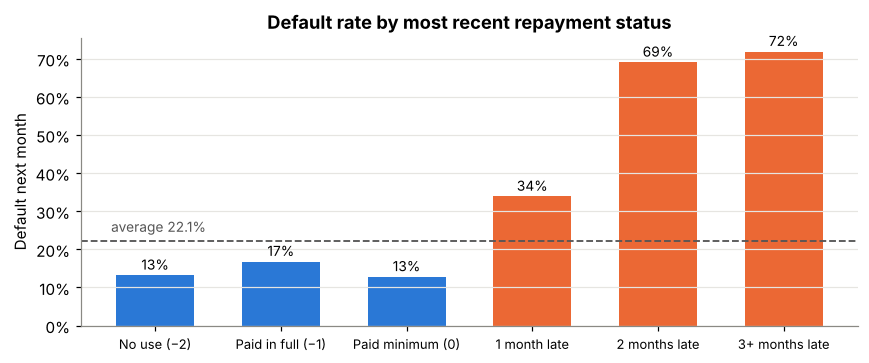

Base default rate: 22.12%


,customers,default_rate
No use (−2),2759,13.200
Paid in full (−1),5686,16.800
Paid minimum (0),14737,12.800
1 month late,3688,33.900
2 months late,2667,69.100
3+ months late,463,71.900


In [3]:
df = raw.copy()
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
df["sex"] = df["SEX"].map({1: "Male", 2: "Female"})
df["age_band"] = pd.cut(df["AGE"], [0, 29, 39, 49, 120], labels=["Under 30", "30-39", "40-49", "50+"])

base_rate = df["default"].mean()
status = df.groupby(df["PAY_1"].clip(-2, 3))["default"].agg(customers="size", default_rate="mean")
status.index = ["No use (−2)", "Paid in full (−1)", "Paid minimum (0)", "1 month late", "2 months late", "3+ months late"]
status["default_rate"] = (100 * status["default_rate"]).round(1)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(status.index, status["default_rate"], color=[BLUE] * 3 + [ORANGE] * 3, width=0.62)
ax.axhline(100 * base_rate, color="#555", lw=1.2, ls="--")
ax.text(-0.35, 100 * base_rate + 2.5, f"average {100 * base_rate:.1f}%", ha="left", fontsize=9, color="#555")
for i, v in enumerate(status["default_rate"]): ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
ax.set_ylabel("Default next month"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Default rate by most recent repayment status"); ax.grid(axis="x", visible=False)
plt.setp(ax.get_xticklabels(), fontsize=8.5)
fig.tight_layout(); fig.savefig("images/default_by_status.png"); plt.show()
print(f"Base default rate: {100 * base_rate:.2f}%")
status

## 2. Features

The model sees credit limit, education, the six months of repayment status, bills and payments, plus five behavioural features a credit analyst would build. **Sex, age and marital status are deliberately left out of the model** so it cannot use them directly. Section 6 tests whether that is enough to make outcomes fair (it often is not, because other features can act as proxies).

In [4]:
df["utilisation"] = df["BILL_AMT1"] / df["LIMIT_BAL"]
df["avg_utilisation"] = df[BILL].mean(axis=1) / df["LIMIT_BAL"]
df["months_late"] = (df[PAY] > 0).sum(axis=1)
df["worst_delay"] = df[PAY].clip(lower=0).max(axis=1)
df["payment_ratio"] = np.where(df["BILL_AMT2"] > 0, df["PAY_AMT1"] / df["BILL_AMT2"].clip(lower=1), 1).clip(0, 5)

FEATURES = ["LIMIT_BAL", "EDUCATION"] + PAY + BILL + PAYAMT + ["utilisation", "avg_utilisation", "months_late", "worst_delay", "payment_ratio"]
X, y = df[FEATURES], df["default"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"train {len(X_train):,} · test {len(X_test):,} · features {len(FEATURES)}")

train 24,000 · test 6,000 · features 25


## 3. Baseline vs gradient boosting

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
booster = xgb.XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                            min_child_weight=5, eval_metric="auc", random_state=42, n_jobs=4)

rows, scores = [], {}
for name, model in [("Logistic regression", logit), ("XGBoost", booster)]:
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]; scores[name] = p
    fpr, tpr, _ = roc_curve(y_test, p)
    top = p >= np.quantile(p, 0.8)
    rows.append({"model": name, "cv_auc_mean": cv_auc.mean(), "cv_auc_sd": cv_auc.std(), "test_auc": roc_auc_score(y_test, p),
                 "test_pr_auc": average_precision_score(y_test, p), "brier": brier_score_loss(y_test, p), "ks": (tpr - fpr).max(),
                 "top20_capture": y_test[top].sum() / y_test.sum(), "top20_precision": y_test[top].mean()})
comparison = pd.DataFrame(rows).set_index("model").round(4)
comparison

,cv_auc_mean,cv_auc_sd,test_auc,test_pr_auc,brier,ks,top20_capture,top20_precision
model,,,,,,,,
Logistic regression,0.759,0.005,0.746,0.504,0.142,0.391,0.483,0.534
XGBoost,0.785,0.005,0.781,0.560,0.135,0.429,0.511,0.565


**How to read this.** ROC AUC measures how well the score ranks defaulters above non-defaulters (0.5 is random). PR AUC focuses on the defaulters, the minority class. Brier score measures probability accuracy (lower is better). KS is the standard credit-scoring separation statistic. *Top 20% capture* is the business number: if the team contacts the riskiest 20% of customers, what share of next month's defaults does it reach?

Cross-validation and test AUC agree closely, so neither model is overfitting.

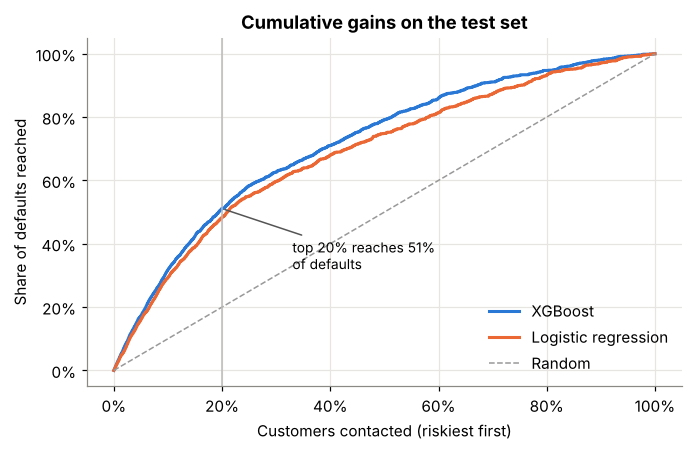

In [6]:
def gains(p, y):
    order = np.argsort(-p); hits = np.cumsum(y.values[order]) / y.sum()
    return np.linspace(0, 1, len(p) + 1), np.r_[0, hits]

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for name, c in [("XGBoost", BLUE), ("Logistic regression", ORANGE)]:
    xs, ys = gains(scores[name], y_test); ax.plot(xs, ys, color=c, lw=2, label=name)
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1, label="Random")
ax.axvline(0.2, color="#bbb", lw=1)
cap = comparison.loc["XGBoost", "top20_capture"]
ax.annotate(f"top 20% reaches {100 * cap:.0f}%\nof defaults", xy=(0.2, cap), xytext=(0.33, 0.32), fontsize=9,
            arrowprops=dict(arrowstyle="-", color="#555"))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Customers contacted (riskiest first)"); ax.set_ylabel("Share of defaults reached")
ax.set_title("Cumulative gains on the test set"); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig("images/gains_curve.png"); plt.show()

## 4. Calibration

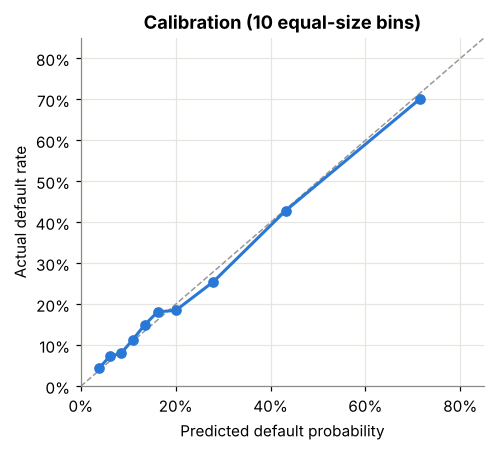

largest gap between predicted and actual: 0.024


,predicted,actual
0,0.038,0.043
1,0.062,0.073
2,0.085,0.080
3,0.109,0.113
4,0.135,0.150
5,0.162,0.182
6,0.200,0.185
7,0.279,0.255
8,0.432,0.428
9,0.716,0.702


In [7]:
p = scores["XGBoost"].astype(float)
frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
calib = pd.DataFrame({"predicted": mean_pred, "actual": frac_pos}).round(3)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1)
ax.plot(mean_pred, frac_pos, "o-", color=BLUE, lw=2)
ax.set_xlim(0, 0.85); ax.set_ylim(0, 0.85)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Predicted default probability"); ax.set_ylabel("Actual default rate")
ax.set_title("Calibration (10 equal-size bins)")
fig.tight_layout(); fig.savefig("images/calibration.png"); plt.show()
print("largest gap between predicted and actual:", float((calib["actual"] - calib["predicted"]).abs().max().round(3)))
calib

## 5. Explainability with SHAP

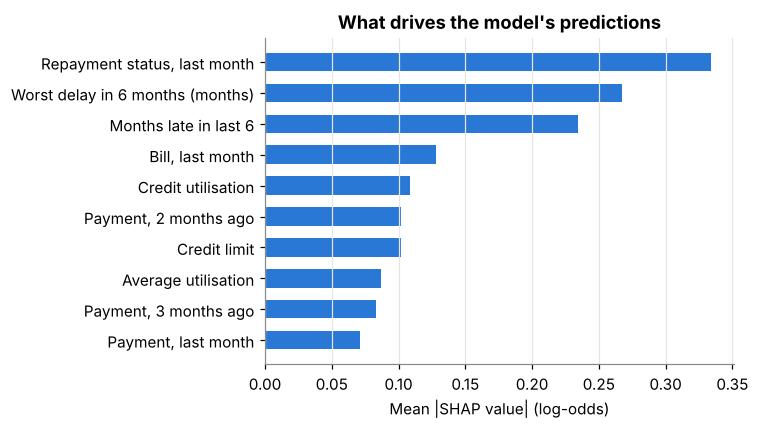

top 3 features carry 42% of total attribution


PAY_1             0.334
worst_delay       0.268
months_late       0.234
BILL_AMT1         0.128
utilisation       0.109
PAY_AMT2          0.102
LIMIT_BAL         0.102
avg_utilisation   0.087
PAY_AMT3          0.083
PAY_AMT1          0.071
dtype: float32

In [8]:
explainer = shap.TreeExplainer(booster)
sv = explainer.shap_values(X_test)
ago = lambda i: "last month" if i == 1 else f"{i} months ago"
labels = {**{f"PAY_{i}": f"Repayment status, {ago(i)}" for i in range(1, 7)}, **{f"BILL_AMT{i}": f"Bill, {ago(i)}" for i in range(1, 7)},
          **{f"PAY_AMT{i}": f"Payment, {ago(i)}" for i in range(1, 7)},
          "worst_delay": "Worst delay in 6 months (months)", "months_late": "Months late in last 6", "utilisation": "Credit utilisation",
          "avg_utilisation": "Average utilisation", "LIMIT_BAL": "Credit limit", "payment_ratio": "Payment ÷ previous bill", "EDUCATION": "Education"}
importance = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES).sort_values(ascending=False)
top = importance.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([labels.get(f, f) for f in top.index], top.values, color=BLUE, height=0.6)
ax.set_xlabel("Mean |SHAP value| (log-odds)"); ax.set_title("What drives the model's predictions"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("images/shap_importance.png"); plt.show()
share_top3 = importance.head(3).sum() / importance.sum()
print(f"top 3 features carry {100 * share_top3:.0f}% of total attribution")
importance.head(10).round(3)

**Reason codes for one customer.** For any flagged customer, SHAP splits the score into each feature's contribution, which can be turned into plain-English reasons for an agent or for the customer.

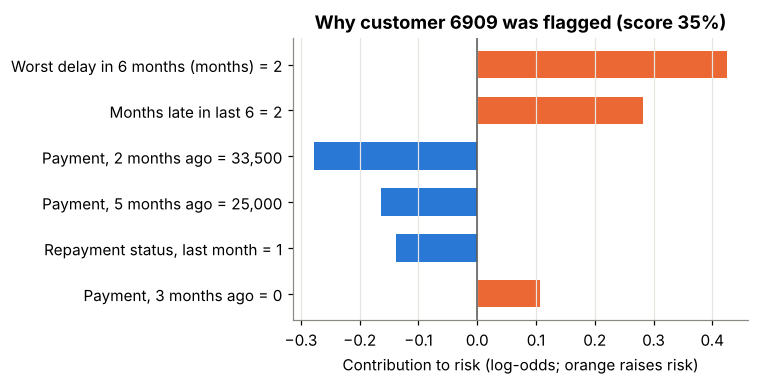

{'customer_id': 6909,
 'score': 0.35,
 'reasons': [{'feature': 'Worst delay in 6 months (months)',
   'value': 2.0,
   'shap': 0.426},
  {'feature': 'Months late in last 6', 'value': 2.0, 'shap': 0.282},
  {'feature': 'Payment, 2 months ago', 'value': 33500.0, 'shap': -0.278},
  {'feature': 'Payment, 5 months ago', 'value': 25000.0, 'shap': -0.164},
  {'feature': 'Repayment status, last month', 'value': 1.0, 'shap': -0.139},
  {'feature': 'Payment, 3 months ago', 'value': 0.0, 'shap': 0.107}]}

In [9]:
risk = pd.Series(p, index=X_test.index)
flag_cut = np.quantile(p, 0.8)
example = risk[(risk > flag_cut) & (risk < flag_cut + 0.05)].index[0]   # a typical flagged customer, near the cut-off
i = X_test.index.get_loc(example)
contrib = pd.Series(sv[i], index=FEATURES)
show = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(6)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh([f"{labels.get(f, f)} = {X_test.loc[example, f]:,.2f}".replace(".00", "") for f in show.index], show.values,
        color=[ORANGE if v > 0 else BLUE for v in show.values], height=0.6)
ax.axvline(0, color="#555", lw=1)
ax.set_xlabel("Contribution to risk (log-odds; orange raises risk)")
ax.set_title(f"Why customer {int(df.loc[example, 'ID'])} was flagged (score {risk[example]:.0%})"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("images/reason_codes.png"); plt.show()
reason_example = {"customer_id": int(df.loc[example, "ID"]), "score": round(float(risk[example]), 3),
                  "reasons": [{"feature": labels.get(f, f), "value": float(X_test.loc[example, f]), "shap": round(float(v), 3)} for f, v in show[::-1].items()]}
reason_example

## 6. Fairness check

Operating point: the team contacts the riskiest 20% of customers. For each group I compare
- **flag rate**: share of the group contacted,
- **true positive rate**: share of the group's defaulters who are caught,
- **false positive rate**: share of the group's non-defaulters contacted unnecessarily,
- **mean score vs actual default rate**: is the model equally calibrated for each group?

The *four-fifths rule* (lowest flag rate ÷ highest ≥ 0.8) is used as a screening heuristic, not a legal test.

In [10]:
test = df.loc[X_test.index, ["sex", "age_band"]].assign(y=y_test.values, score=p, flagged=p >= flag_cut)
def group_metrics(col):
    g = test.groupby(col, observed=True)
    out = pd.DataFrame({
        "customers": g.size(),
        "actual_default_rate": g["y"].mean(),
        "mean_score": g["score"].mean(),
        "flag_rate": g["flagged"].mean(),
        "tpr": g.apply(lambda s: s.loc[s.y == 1, "flagged"].mean()),
        "fpr": g.apply(lambda s: s.loc[s.y == 0, "flagged"].mean()),
    })
    return out.round(3)
fair_sex, fair_age = group_metrics("sex"), group_metrics("age_band")
ratio = lambda t, c: round(float(t[c].min() / t[c].max()), 3)
fairness = {
    "sex_flag_ratio": ratio(fair_sex, "flag_rate"), "age_flag_ratio": ratio(fair_age, "flag_rate"),
    "sex_tpr_gap_pts": round(float(100 * (fair_sex["tpr"].max() - fair_sex["tpr"].min())), 1),
    "age_tpr_gap_pts": round(float(100 * (fair_age["tpr"].max() - fair_age["tpr"].min())), 1),
    "sex_fpr_gap_pts": round(float(100 * (fair_sex["fpr"].max() - fair_sex["fpr"].min())), 1),
    "age_fpr_gap_pts": round(float(100 * (fair_age["fpr"].max() - fair_age["fpr"].min())), 1),
}
display(fair_sex); display(fair_age); fairness

,customers,actual_default_rate,mean_score,flag_rate,tpr,fpr
sex,,,,,,
Female,3598,0.213,0.216,0.190,0.512,0.103
Male,2402,0.234,0.230,0.214,0.510,0.124


,customers,actual_default_rate,mean_score,flag_rate,tpr,fpr
age_band,,,,,,
Under 30,1912,0.223,0.238,0.225,0.560,0.129
30-39,2198,0.206,0.206,0.179,0.490,0.099
40-49,1341,0.233,0.219,0.193,0.481,0.106
50+,549,0.246,0.236,0.213,0.496,0.121


{'sex_flag_ratio': 0.888,
 'age_flag_ratio': 0.796,
 'sex_tpr_gap_pts': 0.2,
 'age_tpr_gap_pts': 7.9,
 'sex_fpr_gap_pts': 2.1,
 'age_fpr_gap_pts': 3.0}

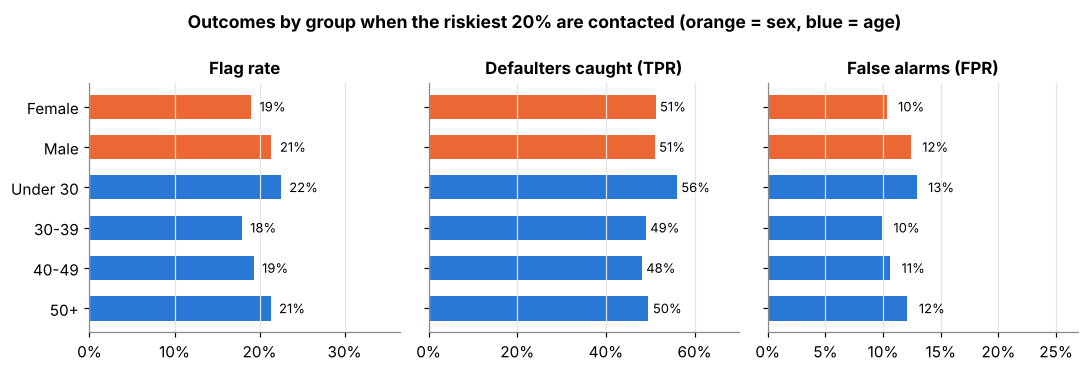

In [11]:
both = pd.concat([fair_sex, fair_age])
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, col, title in zip(axes, ["flag_rate", "tpr", "fpr"], ["Flag rate", "Defaulters caught (TPR)", "False alarms (FPR)"]):
    colors = [ORANGE] * len(fair_sex) + [BLUE] * len(fair_age)
    ax.barh(both.index.astype(str)[::-1], both[col].values[::-1], color=colors[::-1], height=0.6)
    for yy, v in enumerate(both[col].values[::-1]): ax.text(v + 0.01, yy, f"{v:.0%}", va="center", fontsize=8.5)
    ax.set_title(title, fontsize=11); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_xlim(0, both[col].max() + 0.14); ax.grid(axis="y", visible=False)
fig.suptitle("Outcomes by group when the riskiest 20% are contacted (orange = sex, blue = age)", fontsize=11.5, fontweight="bold")
fig.tight_layout(); fig.savefig("images/fairness_by_group.png"); plt.show()

## Findings

- **Recent behaviour dominates.** 22.1% of customers default the following month, but that rises to 69% for customers two months behind. The three repayment-history features carry 42% of the model's total SHAP attribution; demographics were never used.
- **Gradient boosting earns its place, but only modestly.** XGBoost reaches ROC AUC **0.781** on the held-out test set (0.785 ± 0.005 in 5-fold cross-validation) against **0.746** for logistic regression. In business terms, contacting the riskiest 20% reaches **51%** of next month's defaults with XGBoost and 48% with the baseline; 56.5% of contacted customers do default, 2.6 times the average.
- **The probabilities can be trusted.** Calibration stays within 3 percentage points of the actual default rate across all ten score bands, so a score can be used as a probability, for example in expected-loss calculations.
- **Every flag comes with reasons.** SHAP turns each score into contributions that can be read out as reason codes ("two months late in the past six months"; "a large payment two months ago lowered the risk").
- **Leaving out sex and age did not make outcomes identical.** Men and women are caught at the same rate (TPR 51% vs 51%), but men get slightly more false alarms (12% vs 10%). By age, under-30s are flagged most (22.5%) and 30-39s least (17.9%): a flag-rate ratio of **0.80**, right on the four-fifths screening line, and under-30 defaulters are caught 8 points more often than 40-49s. Under-30s are also slightly over-scored (mean score 23.8% vs 22.3% actual).

## Recommendation

Use XGBoost to rank customers for early contact, with SHAP reason codes shown to agents. Because the action is supportive (a call or payment plan), the age gap is acceptable to monitor rather than block, but it should be tracked monthly with a threshold for review. If the score were ever used to cut credit limits, the under-30 over-scoring would need fixing first (for example by recalibrating per group or constraining the model) and a formal fairness review.

## Limitations

- Taiwan, 2005: a different market, regulation and economic cycle from a UK bank today.
- There is no date column, so the split is random rather than out-of-time; a production model would be validated on a later period.
- One-month horizon only; there is no information on loss amounts, so the model ranks risk rather than expected loss.
- Group sizes are modest (549 customers aged 50+ in the test set), so small gaps may be noise.

In [12]:
summary = {
    "quality": quality,
    "base_default_rate_pct": round(100 * base_rate, 2),
    "by_status": [{"group": k, "customers": int(r["customers"]), "default_rate": float(r["default_rate"])} for k, r in status.iterrows()],
    "models": {k: {c: round(float(v), 4) for c, v in r.items()} for k, r in comparison.iterrows()},
    "gains": {name: [round(float(v), 4) for v in gains(scores[name], y_test)[1][np.linspace(0, len(y_test), 11).astype(int)]] for name in scores},
    "calibration": calib.to_dict(orient="records"),
    "shap_top": [{"feature": labels.get(f, f), "importance": round(float(v), 4)} for f, v in importance.head(8).items()],
    "shap_top3_share_pct": round(100 * float(share_top3), 1),
    "reason_example": reason_example,
    "fairness_sex": fair_sex.reset_index().rename(columns={"sex": "group"}).to_dict(orient="records"),
    "fairness_age": fair_age.reset_index().rename(columns={"age_band": "group"}).assign(group=lambda t: t["group"].astype(str)).to_dict(orient="records"),
    "fairness": fairness,
}
json.dump(summary, open("results/summary.json", "w"), indent=1, default=float)
# Per-customer test scores (no IDs or raw features) for the website's scroll visual
test[["score", "y", "sex", "age_band"]].assign(score=lambda t: t["score"].round(4)).rename(columns={"y": "defaulted"}).to_csv("results/test_scores.csv", index=False)
print("saved results/summary.json and results/test_scores.csv")

saved results/summary.json and results/test_scores.csv
